In [1]:
import tensorflow as tf
import os
import re
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Path to your dataset folder
DATASET_DIR = "SkinCancer_Dataset"

# Automatically extract class names
raw_classes = os.listdir(DATASET_DIR)
raw_classes.sort()  # Ensure consistent order

# Clean class names
def clean_class_name(name):
    return re.sub(r"^\d+\.\s*", "", name).split('-')[0].strip()

cleaned_class_names = [clean_class_name(cls) for cls in raw_classes]
print("Classes:", cleaned_class_names)


Classes: ['Benign', 'Malignant']


In [2]:
# Example: define an ImageDataGenerator for augmentation
augmentor = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.2  # For later train/test split
)


In [3]:
# Training generator
train_generator = augmentor.flow_from_directory(
    DATASET_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

# Validation generator
validation_generator = augmentor.flow_from_directory(
    DATASET_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=True
)


Found 9504 images belonging to 2 classes.
Found 2375 images belonging to 2 classes.


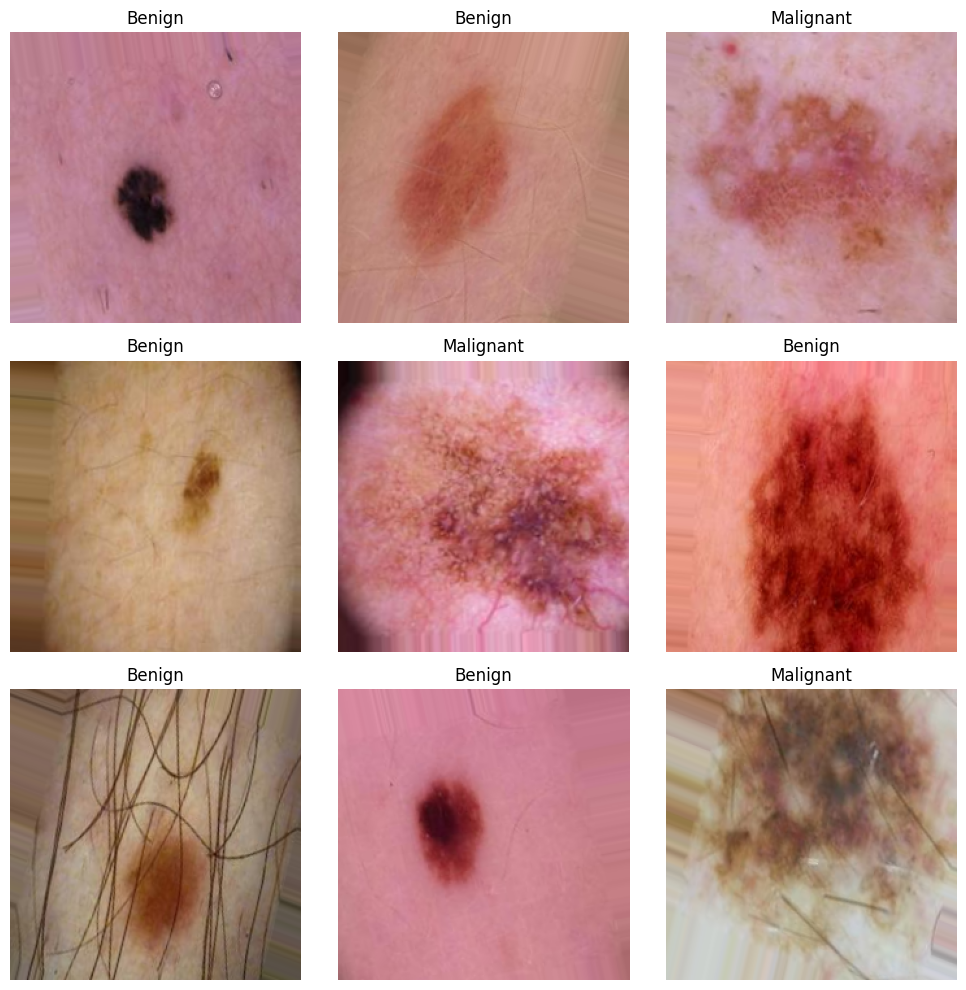

In [4]:
import matplotlib.pyplot as plt

x_batch, y_batch = next(train_generator)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_batch[i])
    plt.title(cleaned_class_names[y_batch[i].argmax()])
    plt.axis('off')
plt.tight_layout()
plt.show()


In [5]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Build model using MobileNetV2 as base
def build_model(input_shape=(224, 224, 3), num_classes=2):
    base_model = MobileNetV2(include_top=False, weights='imagenet', input_shape=input_shape)
    base_model.trainable = False  # Freeze pre-trained layers

    x = GlobalAveragePooling2D()(base_model.output)
    x = Dropout(0.3)(x)
    output = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)
    return model

model = build_model()
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 Conv1 (Conv2D)              (None, 112, 112, 32)         864       ['input_1[0][0]']             
                                                                                                  
 bn_Conv1 (BatchNormalizati  (None, 112, 112, 32)         128       ['Conv1[0][0]']               
 on)                                                                                              
                                                                                                  
 Conv1_relu (ReLU)           (None, 112, 112, 32)         0         ['bn_Conv1[0][0]']        

In [6]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint("best_sskin_cancer_model.h5", monitor="val_accuracy", save_best_only=True)

# Training
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=1,
    callbacks=[early_stop, checkpoint]
)


297/297 [==============================] - ETA: 0s - loss: 0.5676 - accuracy: 0.7159

C:\Users\aamir\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.8_qbz5n2kfra8p0\LocalCache\local-packages\Python38\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


297/297 [==============================] - 689s 2s/step - loss: 0.5676 - accuracy: 0.7159 - val_loss: 0.6280 - val_accuracy: 0.6855


In [7]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Get validation data predictions
y_true = validation_generator.classes
y_pred = model.predict(validation_generator)
y_pred_classes = np.argmax(y_pred, axis=1)

# Classification report
print("Classification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=cleaned_class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)
print("Confusion Matrix:\n", cm)


75/75 [==============================] - 132s 2s/step
Classification Report:

              precision    recall  f1-score   support

      Benign       0.54      0.52      0.53      1257
   Malignant       0.48      0.50      0.49      1118

    accuracy                           0.51      2375
   macro avg       0.51      0.51      0.51      2375
weighted avg       0.51      0.51      0.51      2375

Confusion Matrix:
 [[657 600]
 [561 557]]
